In [1]:
## This notebook is used to plot and save the phase diagrams based on the G-alpha parameter exploration

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.colors import LinearSegmentedColormap
plt.style.use(['science', 'nature'])

plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.title_fontsize": 16,
    "legend.fontsize": 13,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)

cmaps_phase = {
    "pop_A": LinearSegmentedColormap.from_list(
        "pop_A", ["#ffffff", "#8fedbd", "#188b4e"], N=256
    ),
    "pop_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#ffffff", "#ffd4de", "#eaa8b7"], N=256
    ),
    "pop_A_minus_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#eaa8b7", "#ffffff", "#188b4e"], N=256
    ),
}

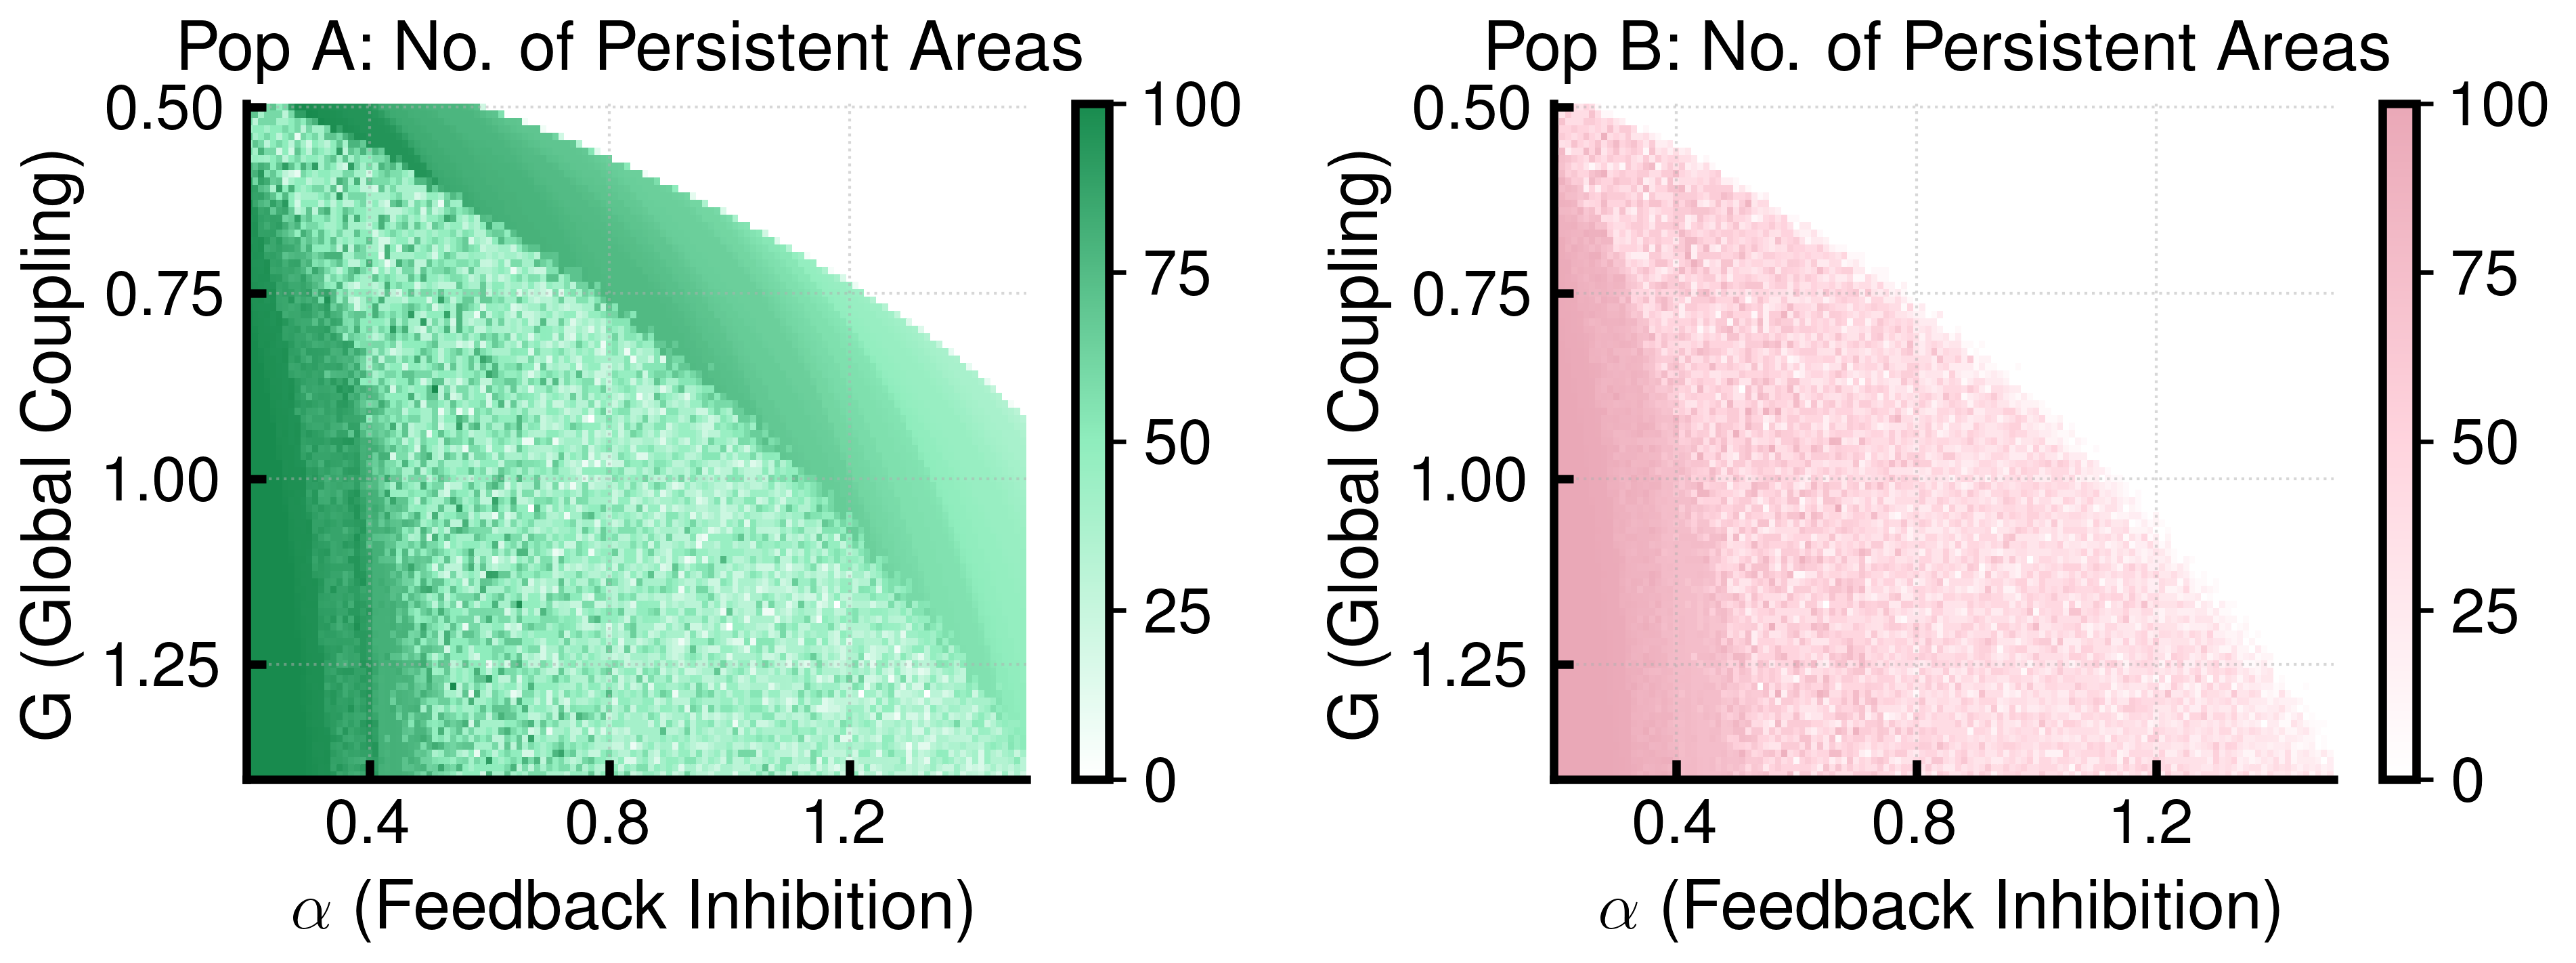

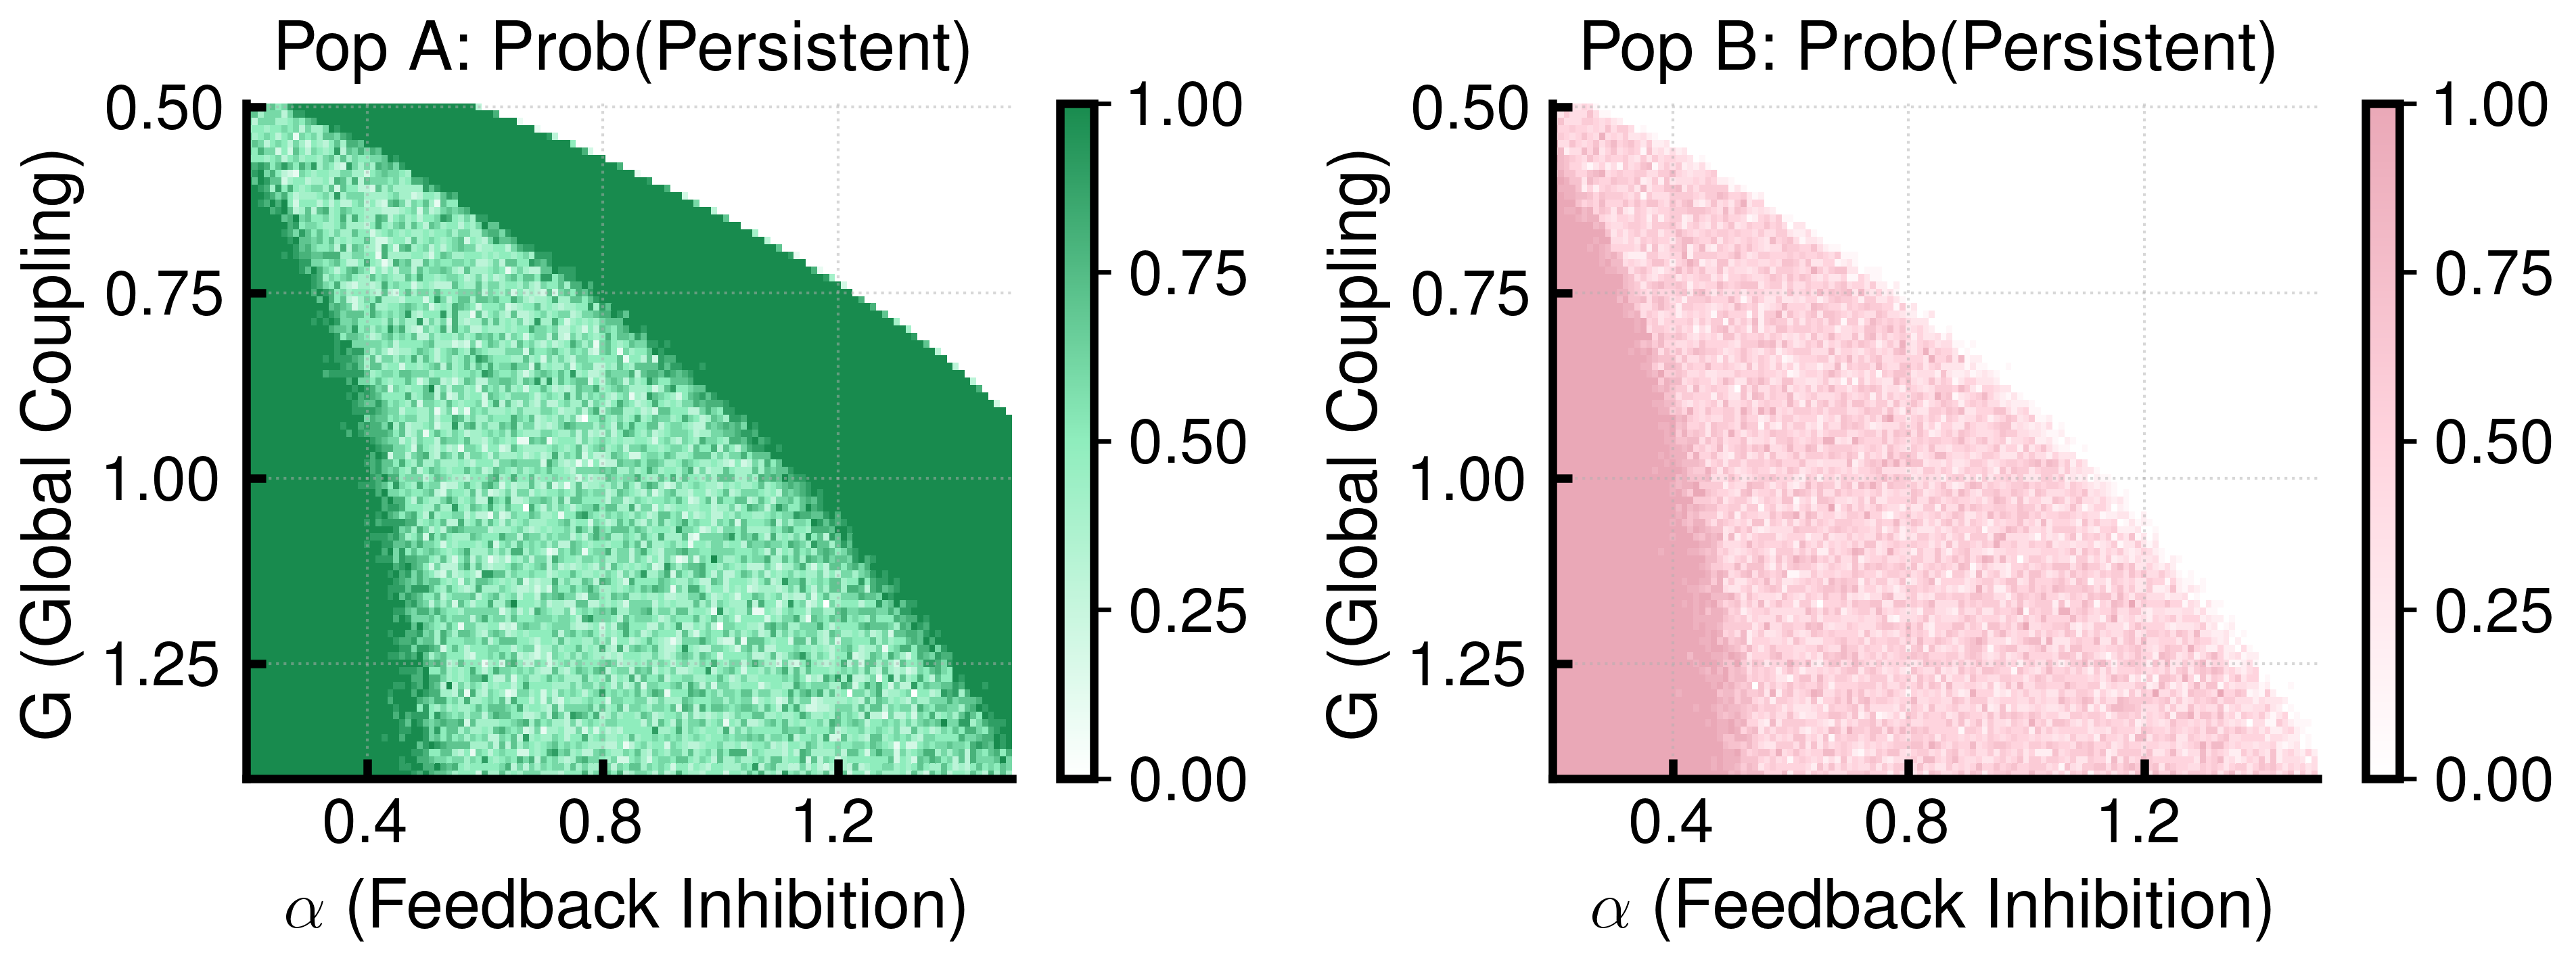

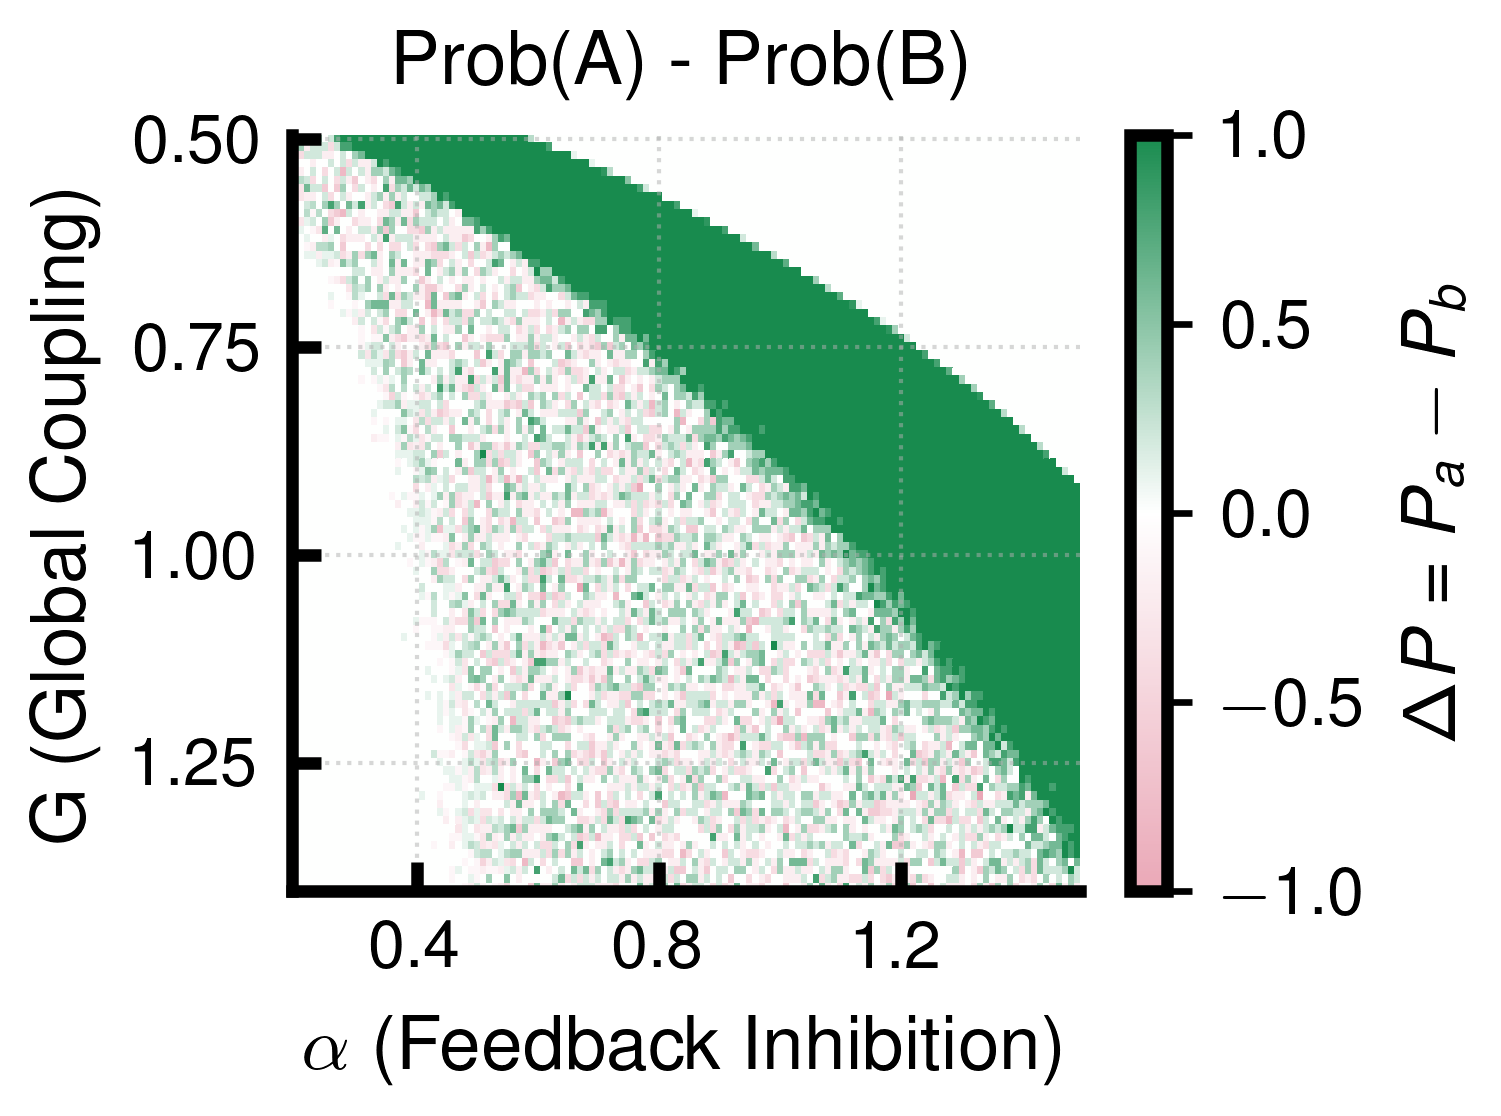

All plots generated and saved in: ../results/phase_diagram_G_alpha/g_alpha_random_seeds_per_G_alpha_corrected_spont_fun


In [4]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

def plot_forbidden_gap_analysis():
    csv_path = '../results/phase_diagram_G_alpha/g_alpha_random_seeds_per_G_alpha_corrected_spont_fun/persistent_activity_stats_all_runs.csv'
    results_dir = '../results/phase_diagram_G_alpha/g_alpha_random_seeds_per_G_alpha_corrected_spont_fun'
    df = pd.read_csv(csv_path, delimiter=",", skipinitialspace=True)
    df = df[df['G'] <= 1.4] # Simulation didn't work for some values above this

    col_g = "G"
    col_alpha = "alpha"
    col_no_persist = "Prob_NoPersist"
    col_a_only = "Prob_A_Only"
    col_b_only = "Prob_B_Only"
    col_a_b = "Prob_A_B"
    col_mean_a = "MeanAreasA_uncond"
    col_mean_b = "MeanAreasB_uncond"

    from matplotlib.ticker import MaxNLocator

    def style_ax(ax, nbins=4):
        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(nbins))
        ax.yaxis.set_major_locator(MaxNLocator(nbins))
        ax.grid(which='major', linestyle=':', alpha=0.5)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.tick_params(top=False, right=False)

    def style_cbar(cbar, nbins=4):
        cbar.locator = MaxNLocator(nbins)
        cbar.update_ticks()
        cbar.ax.minorticks_off()
        cbar.ax.tick_params(which='both', direction='out', length=3, width=0.8)

    # Mean Number of Areas for A and B
    piv_mean_a = df.pivot(index=col_g, columns=col_alpha, values=col_mean_a)
    piv_mean_b = df.pivot(index=col_g, columns=col_alpha, values=col_mean_b)

    plt.figure(figsize=(6.6, 2.6))

    # Mean Areas A
    plt.subplot(1, 2, 1)
    plt.title("Pop A: No. of Persistent Areas")
    imA = plt.pcolor(
        piv_mean_a.columns,
        piv_mean_a.index,
        piv_mean_a.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imA, ax=ax)
    style_cbar(cbar, nbins=4)

    # Mean Areas B
    plt.subplot(1, 2, 2)
    plt.title("Pop B: No. of Persistent Areas")
    imB = plt.pcolor(
        piv_mean_b.columns,
        piv_mean_b.index,
        piv_mean_b.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imB, ax=ax)
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "mean_areas_AB.pdf"))
    plt.show()

    # Probability(A) & Probability(B), plus difference
    # Probability(A) = Probability(A Only) + Probability(A & B)
    # Probability(B) = Probability(B Only) + Probability(A & B)

    df["Probability(A)"] = df[col_a_only] + df[col_a_b]
    df["Probability(B)"] = df[col_b_only] + df[col_a_b]
    df["ProbDiff(A-B)"] = df["Probability(A)"] - df["Probability(B)"]

    piv_probA = df.pivot(index=col_g, columns=col_alpha, values="Probability(A)")
    piv_probB = df.pivot(index=col_g, columns=col_alpha, values="Probability(B)")
    piv_probDiff = df.pivot(index=col_g, columns=col_alpha, values="ProbDiff(A-B)")

    # Plot Probability(A) and Probability(B) side by side
    plt.figure(figsize=(6.6, 2.6))

    # Probability(A)
    plt.subplot(1, 2, 1)
    plt.title("Pop A: Prob(Persistent)")
    imA = plt.pcolor(
        piv_probA.columns,
        piv_probA.index,
        piv_probA.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imA, ax=ax)
    style_cbar(cbar, nbins=4)

    # Probability(B)
    plt.subplot(1, 2, 2)
    plt.title("Pop B: Prob(Persistent)")
    imB = plt.pcolor(
        piv_probB.columns,
        piv_probB.index,
        piv_probB.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imB, ax=ax)
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_A_vs_prob_B.pdf"))
    plt.show()

    # Plot Probability(A)-Probability(B)
    mpl.rcParams.update({
        "font.size": 8,
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
    })
    plt.figure(figsize=(2.6, 2))
    plt.title("Prob(A) - Prob(B)")
    imDiff = plt.pcolor(
        piv_probDiff.columns,
        piv_probDiff.index,
        piv_probDiff.values,
        cmap=cmaps_phase['pop_A_minus_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imDiff, ax=ax)
    cbar.set_label(r'$\Delta P = P_a - P_b$')
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_diff_A_minus_B.pdf"))
    plt.show()

    print("All plots generated and saved in:", results_dir)

if __name__ == "__main__":
    plot_forbidden_gap_analysis()
